# Odporność wyniku v2

Testy odporności dla przebiegu v2 (`topic_v1`, `claims_v2`, `verdict_v2`, Gemma 4 12B; Kukiz15 i Republikanie w prawicy)
i nowego golda: 100 wypowiedzi z warstw v2, etykiety Claude Opus (przebieg 1).

- **Krok 8 (regresja, etykiety modelu):** warianty planu, rozszerzenia i leave-one-speaker-out.
- **Krok 7 (gold):** pojedyncze zmiany sprzeczności i leave-one-out.

Pojedyncze zmiany obejmują wypowiedzi tematyczne według Opusa w warstwach 1 i 2. Warstwa nietematyczna i pojawienie się
sprzeczności w wypowiedziach nietematycznych według Opusa są poza zakresem tego notatnika.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from amc import estimation, robustness, viz
from amc.viz import ACCENT, MUTED, SECOND

viz.setup()
pd.set_option("display.width", 200)

GROUPS = estimation.GROUPS
OUT = ROOT / "data" / "processed" / "results"
REPS = 10_000

labels = pd.read_csv(ROOT / "data" / "processed" / "labels" / "gemma4_12b__verdict_v2__en_embeddinggemma_300m.csv")

V2_GOLD = ROOT / "data" / "gold" / "v2"
design = pd.read_csv(V2_GOLD / "sample.csv")
opus = pd.DataFrame([json.loads(line) for f in sorted((V2_GOLD / "opus" / "out").glob("run1_*.jsonl"))
                     for line in open(f, encoding="utf-8") if line.strip()])
assert sorted(opus["kolejnosc"]) == sorted(design["kolejnosc"])
gold = design.merge(opus[["kolejnosc", "tematyczna", "sprzeczna"]], on="kolejnosc")
gold["sprzeczna"] = gold["sprzeczna"].fillna(0).astype(int)
drawn = gold.groupby(["grupa", "warstwa"])["N_h"].first()
assert drawn.equals(estimation.strata_sizes(labels).set_index(["grupa", "warstwa"])["N_h"].reindex(drawn.index))
len(labels), len(gold)

(43991, 100)

## 1. Krok 8: regresja na etykietach modelu

In [2]:
table = robustness.run(labels)

old_right = labels.assign(grupa=np.where(labels["klub"].isin(robustness.OTHER_RIGHT), "reszta", labels["grupa"]))
fit = robustness.fit(old_right)
main_beta = table.loc[table["wariant"] == "glowny", "beta1"].iloc[0]
table = pd.concat([table, pd.DataFrame([{"wariant": "prawica_zamrozona", "rodzaj": "rozszerzenie",
                                         "opis": "prawica bez Kukiz15 i Republikanów", **fit,
                                         **robustness.criterion(fit["beta1"], main_beta)}])], ignore_index=True)
loso = robustness.leave_one_speaker_out(labels)

table.to_csv(OUT / "odpornosc_v2_regresja.csv", index=False)
loso.to_csv(OUT / "odpornosc_v2_loso.csv", index=False)

view = table[["opis", "rodzaj", "n", "mowcy", "sprzeczne", "beta1", "se", "ci_2.5", "ci_97.5", "p_jednostronne",
              "krotnosc", "odporny"]]
print("werdykt planu:", robustness.verdict(table))
print(f"leave-one-speaker-out: beta1 od {loso['beta1'].min():.3f} do {loso['beta1'].max():.3f}, "
      f"krotność od {loso['krotnosc'].min():.2f} do {loso['krotnosc'].max():.2f}, "
      f"niespełnione: {int((~loso['odporny']).sum())} z {len(loso)}")
view.round(3)

werdykt planu: {'odporny': True, 'niespelnione': []}
leave-one-speaker-out: beta1 od 1.024 do 1.123, krotność od 0.95 do 1.04, niespełnione: 0 z 293


,opis,rodzaj,n,mowcy,sprzeczne,beta1,se,ci_2.5,ci_97.5,p_jednostronne,krotnosc,odporny
0,wynik główny (krok 6),glowny,1775,293,317,1.081,0.145,0.796,1.366,0.0,1.000,True
1,bez Konfederacji (i Konfederacji KP),plan,1497,277,235,0.974,0.172,0.636,1.312,0.0,0.901,True
2,bez PiS (i RozwojPlus),plan,1186,184,189,1.362,0.145,1.079,1.646,0.0,1.260,True
3,pierwsza połowa okresu (do 13.04.2025),plan,949,240,175,0.803,0.189,0.432,1.174,0.0,0.742,True
4,druga połowa okresu (od 14.04.2025),plan,826,209,142,1.430,0.251,0.938,1.921,0.0,1.322,True
5,tylko rola „poseł” (bez ministrów),rozszerzenie,1684,277,310,1.071,0.149,0.779,1.362,0.0,0.990,True
6,sprzeczna = co najmniej 2 twierdzenia sprzeczne,rozszerzenie,1775,293,62,1.608,0.333,0.954,2.261,0.0,1.487,True
7,prawica bez Kukiz15 i Republikanów,rozszerzenie,1775,293,317,0.872,0.219,0.444,1.301,0.0,0.807,True


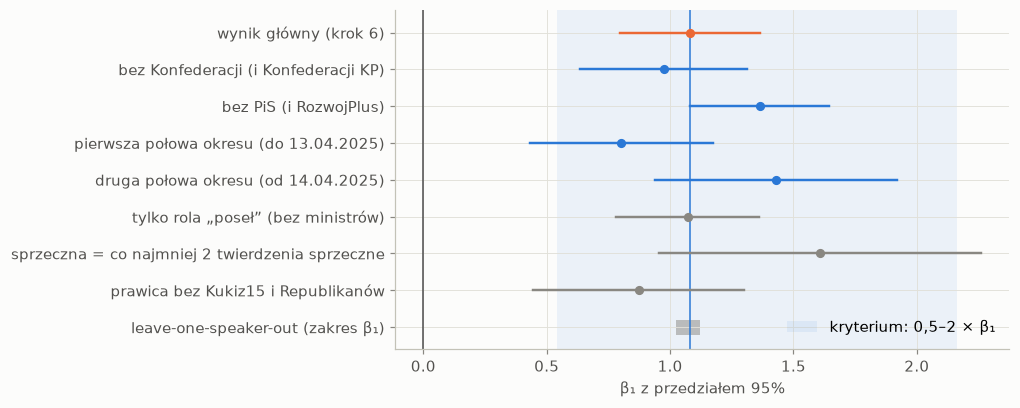

In [3]:
order = table.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.2, 4.0))
y = np.arange(len(order))
ax.axvspan(0.5 * main_beta, 2 * main_beta, color=ACCENT, alpha=0.08, linewidth=0, label="kryterium: 0,5–2 × β₁")
ax.axvline(main_beta, color=ACCENT, linewidth=1)
ax.axvline(0, color="0.3", linewidth=1)
colors = [SECOND if k == "glowny" else ACCENT if k == "plan" else MUTED for k in order["rodzaj"]]
for i, row in order.iterrows():
    ax.plot([row["ci_2.5"], row["ci_97.5"]], [i, i], color=colors[i], linewidth=1.6)
    ax.plot(row["beta1"], i, "o", color=colors[i], markersize=5)
ax.fill_betweenx([-1.2, -0.8], loso["beta1"].min(), loso["beta1"].max(), color=MUTED, alpha=0.5, linewidth=0)
ax.set_yticks(list(y) + [-1], list(order["opis"]) + ["leave-one-speaker-out (zakres β₁)"])
ax.set_ylim(-1.6, len(order) - 0.4)
ax.set_xlabel("β₁ z przedziałem 95%")
ax.legend(frameon=False, loc="lower right")
viz.save(fig, "odpornosc_v2_regresja")
plt.show()

## 2. Krok 7: wynik wyjściowy

In [4]:
base = estimation.summarize(gold, estimation.proportions, reps=REPS)
print(estimation.composition(gold).to_string(index=False))
(100 * base.drop(columns="bootstrap_brak")).round(1)

  grupa  warstwa   N_h  n_h        waga  tematyczne  sprzeczne
prawica        1   231   20   11.550000          18          8
prawica        2   695   15   46.333333          10          0
prawica        3 20266   15 1351.066667           0          0
 reszta        1    86   20    4.300000          16          2
 reszta        2   763   15   50.866667          10          0
 reszta        3 21950   15 1463.333333           0          0


,wartosc,dolna_95_jednostronna,przedzial_2.5,przedzial_97.5
p_prawica,13.8,7.6,6.4,23.2
p_reszta,1.5,0.0,0.0,4.0
roznica,12.3,5.8,4.6,21.7


## 3. Pojedyncze zmiany sprzeczności

Dla każdej wypowiedzi tematycznej według Opusa w warstwach 1 i 2 zmieniamy etykietę sprzeczności na przeciwną i liczymy
krok 7 od nowa (bootstrap z tym samym ziarnem). Waga, warstwa i tematyczność zostają bez zmian.

In [5]:
rows = []
for i in gold.index[(gold["tematyczna"] == 1) & gold["warstwa"].isin([1, 2])]:
    flipped = gold.copy()
    flipped.loc[i, "sprzeczna"] = 1 - gold.loc[i, "sprzeczna"]
    s = estimation.summarize(flipped, estimation.proportions, reps=REPS)
    rows.append({"kolejnosc": gold.loc[i, "kolejnosc"], "grupa": gold.loc[i, "grupa"], "warstwa": gold.loc[i, "warstwa"],
                 "waga": gold.loc[i, "waga"], "sprzeczna_przed": gold.loc[i, "sprzeczna"],
                 "sprzeczna_po": 1 - gold.loc[i, "sprzeczna"], "roznica": s.loc["roznica", "wartosc"],
                 "dolna": s.loc["roznica", "dolna_95_jednostronna"]})
flips = pd.DataFrame(rows)
flips["poparta"] = flips["dolna"] > 0
flips.to_csv(OUT / "odpornosc_v2_zmiany.csv", index=False)

summary = (flips.assign(roznica=100 * flips["roznica"], dolna=100 * flips["dolna"])
           .groupby(["grupa", "warstwa", "sprzeczna_przed", "sprzeczna_po"])
           .agg(n=("dolna", "size"), roznica_min=("roznica", "min"), roznica_max=("roznica", "max"),
                dolna_min=("dolna", "min"), dolna_max=("dolna", "max"), poparta=("poparta", "sum")).round(1))
print(f"zmiany: {len(flips)}, zmieniające werdykt: {int((~flips['poparta']).sum())}")
summary

zmiany: 54, zmieniające werdykt: 10


n  roznica_min  roznica_max  dolna_min  dolna_max  poparta
grupa   warstwa sprzeczna_przed sprzeczna_po                                                             
prawica 1       0               1             10         14.0         14.0        7.2        7.3       10
                1               0              8         10.6         10.6        4.2        4.3        8
        2       0               1             10         19.2         19.2        8.0        8.2       10
reszta  1       0               1             14         11.5         11.5        4.8        4.9       14
                1               0              2         13.0         13.0        6.7        6.7        2
        2       0               1             10          3.5          3.5      -13.7      -12.8        0

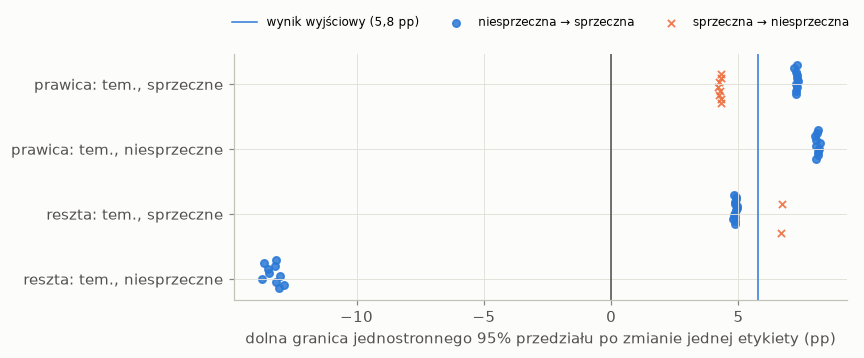

In [6]:
lower = 100 * base.loc["roznica", "dolna_95_jednostronna"]
groups = [("prawica", 1), ("prawica", 2), ("reszta", 1), ("reszta", 2)]
names = {1: "tem., sprzeczne", 2: "tem., niesprzeczne"}
fig, ax = plt.subplots(figsize=(7.2, 2.9))
ax.axvline(0, color="0.3", linewidth=1)
ax.axvline(lower, color=ACCENT, linewidth=1, label=f"wynik wyjściowy ({lower:.1f} pp)".replace(".", ","))
for row, (g, h) in enumerate(groups):
    part = flips[(flips["grupa"] == g) & (flips["warstwa"] == h)]
    for value, marker, color, label in ((0, "o", ACCENT, "niesprzeczna → sprzeczna"), (1, "x", SECOND, "sprzeczna → niesprzeczna")):
        p = part[part["sprzeczna_przed"] == value]
        jitter = np.linspace(-0.22, 0.22, len(p)) if len(p) > 1 else np.zeros(len(p))
        ax.scatter(100 * p["dolna"], row + jitter + (0.07 if value else -0.07), marker=marker, color=color, s=22,
                   alpha=0.85, linewidths=1.2, label=label if row == 0 else None)
ax.set_yticks(range(4), [f"{g}: {names[h]}" for g, h in groups])
ax.invert_yaxis()
ax.set_xlabel("dolna granica jednostronnego 95% przedziału po zmianie jednej etykiety (pp)")
handles, texts = ax.get_legend_handles_labels()
unique = dict(zip(texts, handles))
ax.legend(unique.values(), unique.keys(), frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=3, fontsize=8)
viz.save(fig, "odpornosc_v2_zmiany")
plt.show()

## 4. Leave-one-out

Usuwamy po jednej wypowiedzi ze 100; waga jej warstwy to wtedy `N_h / (n_h - 1)`.

In [7]:
rows = []
for i in gold.index:
    cell = (gold["grupa"] == gold.loc[i, "grupa"]) & (gold["warstwa"] == gold.loc[i, "warstwa"])
    reduced = gold.copy()
    reduced.loc[cell, "n_h"] = reduced.loc[cell, "n_h"] - 1
    reduced.loc[cell, "waga"] = reduced.loc[cell, "N_h"] / reduced.loc[cell, "n_h"]
    reduced = reduced.drop(index=i)
    s = estimation.summarize(reduced, estimation.proportions, reps=2_000)
    rows.append({"kolejnosc": gold.loc[i, "kolejnosc"], "grupa": gold.loc[i, "grupa"], "warstwa": gold.loc[i, "warstwa"],
                 "tematyczna": gold.loc[i, "tematyczna"], "sprzeczna": gold.loc[i, "sprzeczna"],
                 "roznica": s.loc["roznica", "wartosc"], "dolna": s.loc["roznica", "dolna_95_jednostronna"]})
loo = pd.DataFrame(rows)
loo["poparta"] = loo["dolna"] > 0
loo.to_csv(OUT / "odpornosc_v2_loo.csv", index=False)
print(f"różnica od {100 * loo['roznica'].min():.1f} do {100 * loo['roznica'].max():.1f} pp; "
      f"dolna granica od {100 * loo['dolna'].min():.1f} do {100 * loo['dolna'].max():.1f} pp; "
      f"warianty niepoparte: {int((~loo['poparta']).sum())} z {len(loo)}")
(100 * loo.groupby(["grupa", "warstwa"])[["roznica", "dolna"]].agg(["min", "max"])).round(1)

różnica od 11.2 do 13.0 pp; dolna granica od 4.5 do 6.7 pp; warianty niepoparte: 0 z 100


roznica       dolna     
                    min   max   min  max
grupa   warstwa                         
prawica 1          11.2  13.0   4.5  6.5
        2          11.6  12.6   5.7  6.3
        3          12.3  12.3   5.9  5.9
reszta  1          12.2  13.0   5.7  6.7
        2          12.2  12.4   5.7  6.0
        3          12.3  12.3   5.6  6.1

## Wnioski

1. **Regresja (krok 8).** Wszystkie warianty planu i rozszerzenia spełniają kryterium: ten sam znak i krotność od 0,74 do 1,49.
   Usunięcie jednego mówcy daje β₁ od 1,02 do 1,12. Dotyczy to jednak świata etykiet modelu, a nie wyniku rozstrzygającego.
2. **Pojedyncze zmiany (krok 7).** 44 z 54 zmian zachowują werdykt, a 10 go odwraca. Są to wszystkie wypowiedzi tematyczne reszty
   z warstwy 2, które po zmianie stają się sprzeczne: różnica spada z 12,3 do 3,5 pp, a dolna granica poniżej zera (około −13 pp).
   Powód: waga 50,87 przy $\hat{S}_{\text{reszta}} = 8{,}6$. W pozostałych warstwach dolna granica zostaje dodatnia.
3. **Leave-one-out.** Usunięcie żadnej ze 100 wypowiedzi nie zmienia werdyktu (dolna granica od 4,5 do 6,7 pp).
4. **Poza zakresem.** Nie badamy warstwy nietematycznej ani wypowiedzi nietematycznych według Opusa, więc ten notatnik nie wyczerpuje
   wrażliwości na pojedyncze etykiety.